# Chapitre 2 - Cours 4 : L'échantillonnage et la nature probabiliste des modèles

Pour l'autrice, l'échantillonnage est l'un des concepts les plus sous-estimés de l'IA :
il explique des comportements déroutants (incohérences, hallucinations) et, bien
choisi, améliore nettement un modèle pour un effort minime. Ce notebook couvre la
section *Sampling* du livre :

- *Sampling Fundamentals* : logits, softmax, décodage glouton ;
- *Sampling Strategies* : température, logprobs, top-k, top-p, conditions d'arrêt ;
- *Test Time Compute* : best-of-N, sélection par logprob, vote majoritaire
  (*self-consistency*), mesurés sur un vrai modèle ;
- *Structured Outputs* : prompt, post-traitement, et **décodage contraint** par masque de
  logits (JSON et liste d'étiquettes) ;
- *The Probabilistic Nature of AI* : incohérence et hallucination, mesurées.

**Plan.** 1. Des logits aux probabilités ; 2. La température ; 3. Les logprobs ;
4. Top-k, top-p et min-p ; 5. Conditions d'arrêt ; 6. Test time compute ; 7. Sorties
structurées ; 8. Nature probabiliste : l'incohérence ; 9. Les hallucinations ; Synthèse.

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch02_modeles as m
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.max_colwidth", 110)
BASE_QWEN = "Qwen/Qwen2.5-0.5B"
tok, model = llm.load(llm.SMALL)


def short(txt, n=160):
    txt = " ".join(str(txt).split())
    return txt if len(txt) <= n else txt[:n] + " [...]"


def chat_logits(prompt, model_id=llm.SMALL, prefix=""):
    """Logits complets du prochain token après un prompt mis en forme (et un début de réponse optionnel)."""
    t, mdl = llm.load(model_id)
    text = t.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False,
                                 add_generation_prompt=True) + prefix
    ids = t(text, return_tensors="pt", add_special_tokens=False)["input_ids"].to(mdl.device)
    with torch.no_grad():
        return mdl(ids).logits[0, -1].float().cpu().numpy()

## 1. Des logits aux probabilités (section *Sampling Fundamentals*)

Un classifieur de spam calcule deux probabilités (spam, non-spam) puis décide. Un modèle
de langue fait de même sur **tout son vocabulaire** : pour chaque contexte, il produit un
vecteur de **logits** $x \in \mathbb R^{V}$, un score par token (151 936 pour Qwen2.5).
Les logits ne sont pas des probabilités : ils peuvent être négatifs et ne somment pas à
1. La **softmax** les transforme :
$$p_i = \operatorname{softmax}(x)_i = \frac{e^{x_i}}{\sum_{j=1}^V e^{x_j}} .$$
Regardons la vraie distribution du modèle de base Qwen2.5-0.5B après l'exemple du
livre, « My favorite color is ».

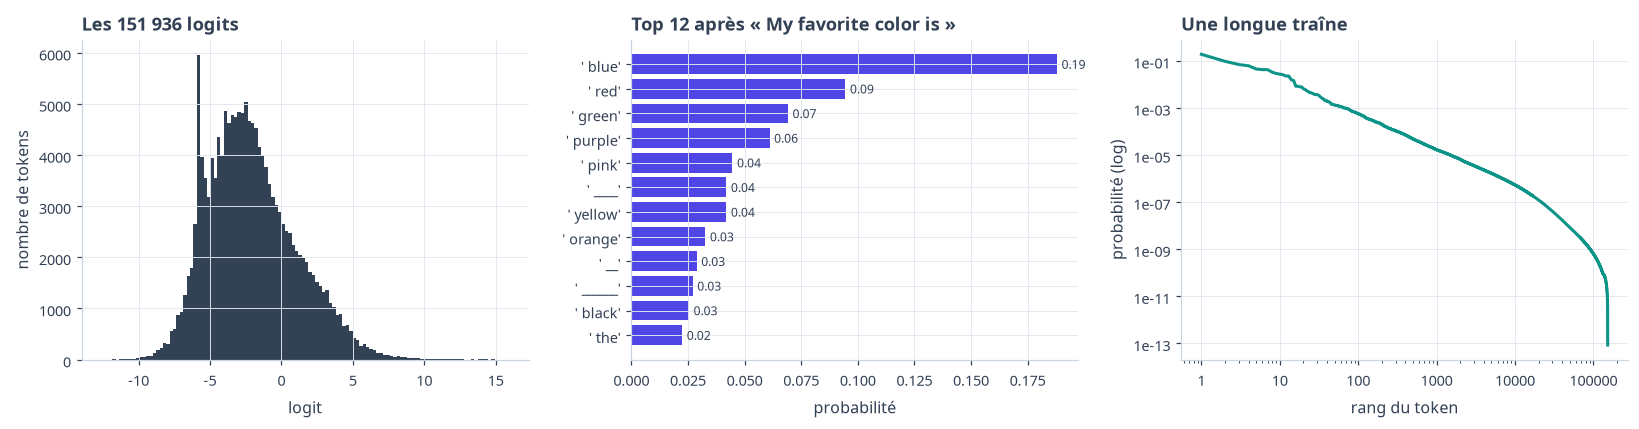

somme des probabilités : 1.000000 ; tokens nécessaires pour 90 % de la masse : 105


In [2]:
ctx = "My favorite color is"
z = llm.full_logits(ctx, BASE_QWEN)
p = llm.softmax(z)
tok_b, _ = llm.load(BASE_QWEN)
order = np.argsort(-p)
top = order[:12]
labels_top = [repr(tok_b.decode([i])) for i in top]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
ax.hist(z, bins=120, color=SLATE)
ax.set_xlabel("logit"); ax.set_ylabel("nombre de tokens"); ax.set_title(f"Les {len(z):,} logits".replace(",", " "))
ax = axes[1]
ax.barh(labels_top[::-1], p[top][::-1], color=INDIGO)
annotate_bars(ax, "{:.2f}", fontsize=8)
ax.set_xlabel("probabilité"); ax.set_title(f"Top 12 après « {ctx} »")
ax = axes[2]
ax.loglog(np.arange(1, len(p) + 1), p[order], color=TEAL)
ax.set_xlabel("rang du token"); ax.set_ylabel("probabilité (log)"); ax.set_title("Une longue traîne")
m.plain_log_axis(ax); m.plain_log_axis(ax, "y", lambda v: f"{v:.0e}")
plt.tight_layout(); plt.show()
print(f"somme des probabilités : {p.sum():.6f} ; tokens nécessaires pour 90 % de la masse : "
      f"{np.searchsorted(np.cumsum(p[order]), 0.9) + 1}")

Le **décodage glouton** (*greedy*) prend toujours le token le plus probable : parfait pour
un classifieur, mais pour un modèle de langue il produit des textes ternes, toujours les
mêmes mots communs. On préfère **échantillonner** selon la distribution : si « red » a
30 % de chances, il sera choisi 30 % du temps. Dix tirages indépendants :

In [3]:
r = np.random.default_rng(1)
draws = [tok_b.decode([m.sample_token(z, r)]) for _ in range(10)]
print("glouton     :", repr(tok_b.decode([int(np.argmax(z))])))
print("échantillons:", draws)

glouton     : ' blue'
échantillons: [' blue', ' Zh', ' __', ' ______', ' known', ' blue', ' purple', ' green', ' blue', ' a']


> **À retenir.** Le modèle ne produit pas un mot mais une **distribution** sur tout le
> vocabulaire. Le glouton prend le maximum ; l'échantillonnage tire au sort selon les
> probabilités, et c'est là que s'introduit l'aléa.

## 2. La température (section *Temperature*)

Pour rendre les réponses plus ou moins « créatives », on divise les logits par une
**température** $T > 0$ avant la softmax :
$$p_i(T) = \frac{e^{x_i / T}}{\sum_j e^{x_j / T}} .$$
Le rapport de deux probabilités vaut $p_i/p_j = e^{(x_i - x_j)/T}$ : une basse température
amplifie les écarts (le favori rafle tout), une haute température les écrase (vers
l'uniforme). L'ordre des tokens, lui, ne change jamais. Exemple du livre : deux tokens A et
B de logits $[1, 2]$.

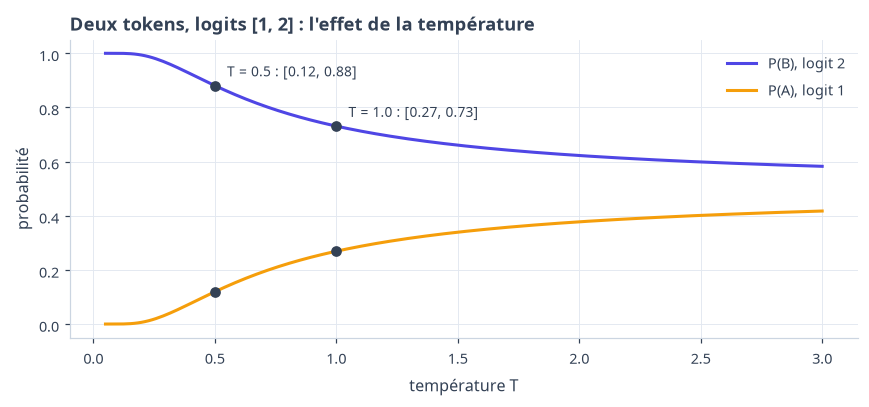

In [4]:
Ts = np.linspace(0.05, 3, 200)
pAB = np.array([llm.softmax(np.array([1.0, 2.0]), t) for t in Ts])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(Ts, pAB[:, 1], color=INDIGO, label="P(B), logit 2")
ax.plot(Ts, pAB[:, 0], color=AMBER, label="P(A), logit 1")
for t in [0.5, 1.0]:
    pb = llm.softmax(np.array([1.0, 2.0]), t)
    ax.plot([t, t], [pb[0], pb[1]], "o", color=SLATE)
    ax.annotate(f"T = {t} : [{pb[0]:.2f}, {pb[1]:.2f}]", (t, pb[1]), xytext=(8, 6), textcoords="offset points",
                fontsize=9)
ax.set_xlabel("température T"); ax.set_ylabel("probabilité"); ax.legend()
ax.set_title("Deux tokens, logits [1, 2] : l'effet de la température")
plt.tight_layout(); plt.show()

Sur la vraie distribution, et en mesurant l'**entropie** $H = -\sum_i p_i \log p_i$
(le « nombre effectif » de choix vaut $e^H$) :

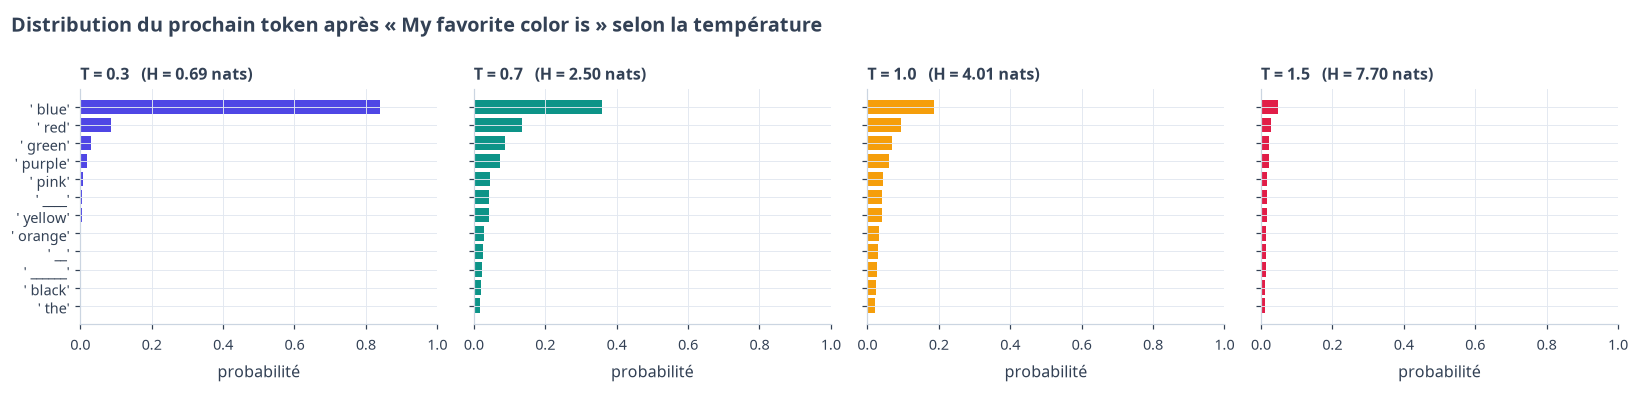

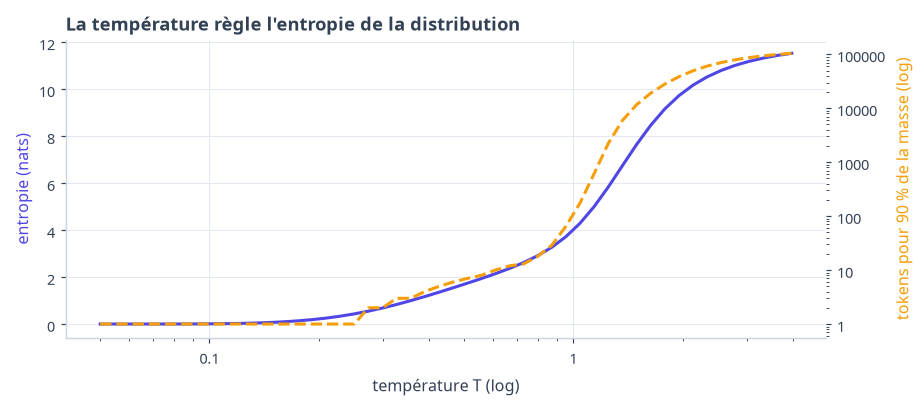

In [5]:
temps = [0.3, 0.7, 1.0, 1.5]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, t, c in zip(axes, temps, [INDIGO, TEAL, AMBER, ROSE]):
    pt = llm.softmax(z, t)
    ax.barh(labels_top[::-1], pt[top][::-1], color=c)
    ax.set_title(f"T = {t}   (H = {m.entropy(pt):.2f} nats)", fontsize=10.5)
    ax.set_xlim(0, 1); ax.set_xlabel("probabilité")
finish(fig, f"Distribution du prochain token après « {ctx} » selon la température")
plt.show()

Tgrid = np.logspace(-1.3, 0.6, 50)
H = [m.entropy(llm.softmax(z, t)) for t in Tgrid]
n90 = [np.searchsorted(np.cumsum(np.sort(llm.softmax(z, t))[::-1]), 0.9) + 1 for t in Tgrid]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.semilogx(Tgrid, H, color=INDIGO, label="entropie (nats)")
ax.set_xlabel("température T (log)"); ax.set_ylabel("entropie (nats)", color=INDIGO)
ax2 = ax.twinx(); ax2.grid(False)
ax2.semilogx(Tgrid, n90, color=AMBER, ls="--", label="tokens pour 90 % de la masse")
ax2.set_yscale("log"); ax2.set_ylabel("tokens pour 90 % de la masse (log)", color=AMBER)
m.plain_log_axis(ax2, "y"); m.plain_log_axis(ax)
ax.set_title("La température règle l'entropie de la distribution")
plt.tight_layout(); plt.show()

L'entropie croît **toujours** avec la température : on montre (exercice 2.8) que
$\frac{dH}{dT} = \frac{\operatorname{Var}_{p(T)}(x)}{T^3} \ge 0$. À $T = 0$, on ne peut pas
diviser par zéro : par convention, on prend l'argmax (décodage glouton). Les API limitent
souvent $T$ à $[0, 2]$ ; 0,7 est un réglage courant pour les usages créatifs. Effet sur des
générations complètes (notre propre boucle de génération `m.generate_custom`, graine fixée) :

In [6]:
prompt_creatif = "Écris la première phrase d'un roman de science-fiction."
rows = []
for t in [0.0, 0.7, 1.2, 2.0]:
    txt, lps = m.generate_custom(prompt_creatif, max_new_tokens=40, temperature=t, seed=3)
    rows.append({"T": t, "génération": short(txt, 170), "logprob moyenne": round(float(lps.mean()), 2)})
pd.DataFrame(rows)

,T,génération,logprob moyenne
0,0.0,"""Le temps est perdu, mais la vie continue.""",-1.26
1,0.7,"""Quand la mer se transforme en ressemblance, les êtres humains sont effaçés.""",-1.72
2,1.2,"""Le retour des anges est un épisode magique et espagnolic de cyberspace""",-2.63
3,2.0,Intella Nay PayPal met tous ces seems rejuvenated spectrum antementionné piston اللجborn jejecure falling....,-11.84


À $T = 0$ la phrase est la plus « probable » ; vers $T = 1$ elle varie tout en restant
cohérente ; à $T = 2$, les tokens rares envahissent la génération, qui devient incohérente
(la logprob moyenne sous le modèle s'effondre).

> **À retenir.** La température divise les logits : $T < 1$ concentre la distribution,
> $T > 1$ l'aplatit. Elle règle le compromis entre cohérence (basse) et diversité
> (haute) ; $T = 0$ signifie décodage glouton.

## 3. Les logprobs

Les API renvoient souvent des **logprobs**, des probabilités en échelle logarithmique.
Raison : avec 100 000 tokens, beaucoup de probabilités sont minuscules, et leur produit
sur une séquence **sous-dépasse** (*underflow*) la précision machine. Démonstration avec
les probabilités réelles des tokens d'un texte d'environ 200 tokens :

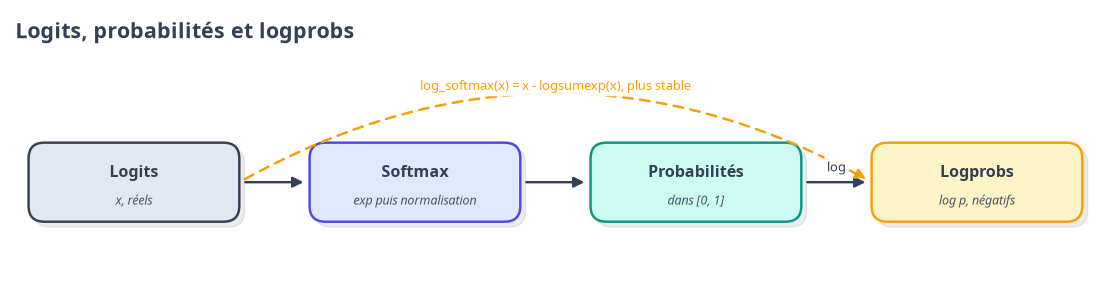

In [7]:
d = Diagram(12.5, 2.4, title="Logits, probabilités et logprobs")
d.flow([("lg", "Logits", "x, réels"), ("sm", "Softmax", "exp puis normalisation"), ("pr", "Probabilités", "dans [0, 1]"),
        ("lp", "Logprobs", "log p, négatifs")], y=1.0, x0=1.4, dx=3.2, w=2.4,
       labels=["", "", "log"], colors=[SLATE, INDIGO, TEAL, AMBER])
d.arrow("lg", "lp", "log_softmax(x) = x - logsumexp(x), plus stable", rad=-0.28, color=AMBER, style="dashed",
        label_offset=(0, 0.1))
d.show()

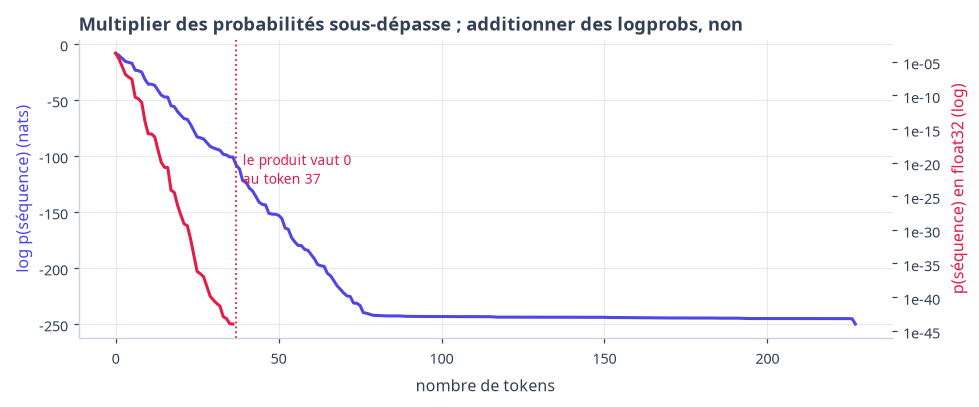

228 tokens : log p(séquence) = -250.4 nats, soit p = 10^-109


In [8]:
long_text = (" ".join(m.PARALLEL_CORPUS["en"]) + " The committee will publish its final report next week, "
             "after several months of public consultation with residents, local businesses and schools. ") * 3
toks_lt, lp_lt = llm.token_logprobs(long_text, BASE_QWEN)
probs32 = np.exp(lp_lt).astype(np.float32)
prod32 = np.cumprod(probs32)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(np.cumsum(lp_lt), color=INDIGO, label="somme des logprobs (stable)")
ax.set_xlabel("nombre de tokens"); ax.set_ylabel("log p(séquence) (nats)", color=INDIGO)
ax2 = ax.twinx(); ax2.grid(False)
ax2.semilogy(np.where(prod32 > 0, prod32, np.nan), color=ROSE, label="produit des probabilités (float32)")
ax2.set_ylabel("p(séquence) en float32 (log)", color=ROSE); m.plain_log_axis(ax2, "y", lambda v: f"{v:.0e}")
first0 = int(np.argmax(prod32 == 0)) if (prod32 == 0).any() else None
if first0:
    ax.axvline(first0, color=ROSE, ls=":", lw=1.2)
    ax.text(first0 + 2, np.cumsum(lp_lt).min() * 0.5, f"le produit vaut 0\nau token {first0}", color=ROSE, fontsize=9)
ax.set_title("Multiplier des probabilités sous-dépasse ; additionner des logprobs, non")
plt.tight_layout(); plt.show()
print(f"{len(lp_lt)} tokens : log p(séquence) = {lp_lt.sum():.1f} nats, soit p = 10^{lp_lt.sum() / np.log(10):.0f}")

(La courbe bleue s'aplatit après la première occurrence du paragraphe : celui-ci étant
répété trois fois, le modèle le recopie presque sans erreur, grâce aux têtes d'induction
du cours 1.) La probabilité réelle de ce texte, de l'ordre de $10^{-100}$ ou moins, n'est pas
représentable en float32 (plus petit nombre normal : $\approx 10^{-38}$) : le produit
devient exactement 0 après quelques dizaines de tokens. La somme des logprobs, elle, ne
pose aucun problème. Les logprobs servent partout dans le livre : classification,
évaluation (chapitre 3), sélection de sorties (section 6). Hélas, beaucoup d'API les
exposent peu (20 meilleurs tokens chez OpenAI au moment de l'écriture, aucun chez
Anthropic), en partie pour compliquer la copie des modèles.

> **À retenir.** On manipule les probabilités de séquences en **logprobs** : la
> log-probabilité d'une séquence est la somme des logprobs de ses tokens.

## 4. Top-k, top-p et min-p (sections *Top-k* et *Top-p*)

**Top-k** ne garde que les $k$ logits les plus grands (typiquement 50 à 500) avant la
softmax, ce qui réduit le calcul et coupe la longue traîne. Mais $k$ est **fixe**, alors
que le nombre de suites raisonnables varie : deux pour « Aimez-vous la musique ? Répondez
par oui ou non », des milliers pour « Quel est le sens de la vie ? ».

**Top-p** (*nucleus sampling*) garde le **plus petit ensemble** de tokens dont la
probabilité cumulée atteint $p$ (souvent 0,9 à 0,95) : sa taille s'adapte au contexte.
**Min-p** garde les tokens dont la probabilité dépasse une fraction du meilleur. Nos
implémentations (`m.top_k_filter`, `m.top_p_filter`, `m.min_p_filter`) mettent les
logits exclus à $-\infty$. Comparons la taille du noyau pour les deux prompts du livre,
posés au modèle de base Qwen2.5-0.5B au format « Q: ... A: » (un modèle Instruct commence
presque toujours ses réponses par les mêmes formules, ce qui masque l'effet au premier
token).

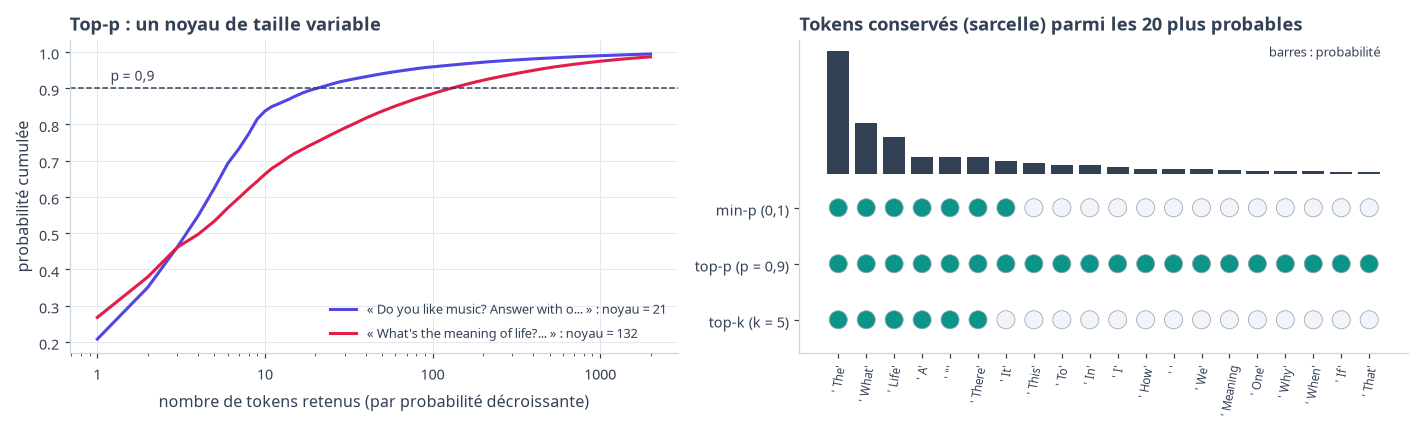

In [9]:
prompts_np = {"Do you like music? Answer with only yes or no.": INDIGO,
              "What's the meaning of life?": ROSE}
qa = lambda q: f"Q: {q}\nA:"
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for prompt, c in prompts_np.items():
    zl = llm.full_logits(qa(prompt), BASE_QWEN)
    pl = np.sort(llm.softmax(zl))[::-1]
    cum = np.cumsum(pl)
    k90 = int(np.isfinite(m.top_p_filter(zl, 0.9)).sum())
    axes[0].semilogx(np.arange(1, 2001), cum[:2000], color=c, label=f"« {prompt[:32]}... » : noyau = {k90}")
axes[0].axhline(0.9, color=SLATE, ls="--", lw=1); axes[0].text(1.2, 0.92, "p = 0,9", fontsize=9)
axes[0].set_xlabel("nombre de tokens retenus (par probabilité décroissante)")
axes[0].set_ylabel("probabilité cumulée"); m.plain_log_axis(axes[0]); axes[0].legend(fontsize=8.5, loc="lower right")
axes[0].set_title("Top-p : un noyau de taille variable")
zl = llm.full_logits(qa("What's the meaning of life?"), BASE_QWEN)
pl = llm.softmax(zl)
top20 = np.argsort(-pl)[:20]
kept = {"top-k (k = 5)": np.isfinite(m.top_k_filter(zl, 5)), "top-p (p = 0,9)": np.isfinite(m.top_p_filter(zl, 0.9)),
        "min-p (0,1)": np.isfinite(m.min_p_filter(zl, 0.1))}
for j, (name, mask) in enumerate(kept.items()):
    axes[1].scatter(np.arange(20), np.full(20, j), c=[TEAL if mask[i] else LIGHT[GRAY] for i in top20], s=140,
                    edgecolors=GRAY, linewidths=0.5)
axes[1].bar(np.arange(20), pl[top20] / pl[top20].max() * 2.2, bottom=2.6, color=SLATE)
axes[1].set_yticks([0, 1, 2], list(kept)); axes[1].set_ylim(-0.6, 5.0)
axes[1].set_xticks(np.arange(20), [repr(tok_b.decode([i]))[:9] for i in top20], rotation=80, fontsize=7.5)
axes[1].set_title("Tokens conservés (sarcelle) parmi les 20 plus probables"); axes[1].grid(False)
axes[1].text(19.4, 4.7, "barres : probabilité", ha="right", fontsize=8.5, color=SLATE)
plt.tight_layout(); plt.show()

Pour la question fermée, le noyau à 90 % tient en une vingtaine de tokens (les variantes
de « yes » et « no » : majuscule, espace...) ; pour la question ouverte, il en contient
plus d'une centaine. Le noyau varie aussi **d'une position à l'autre**
d'un même texte : mesurons sa taille à chaque token d'une phrase (le modèle de base lit
la phrase en *teacher forcing*, une seule passe avant).

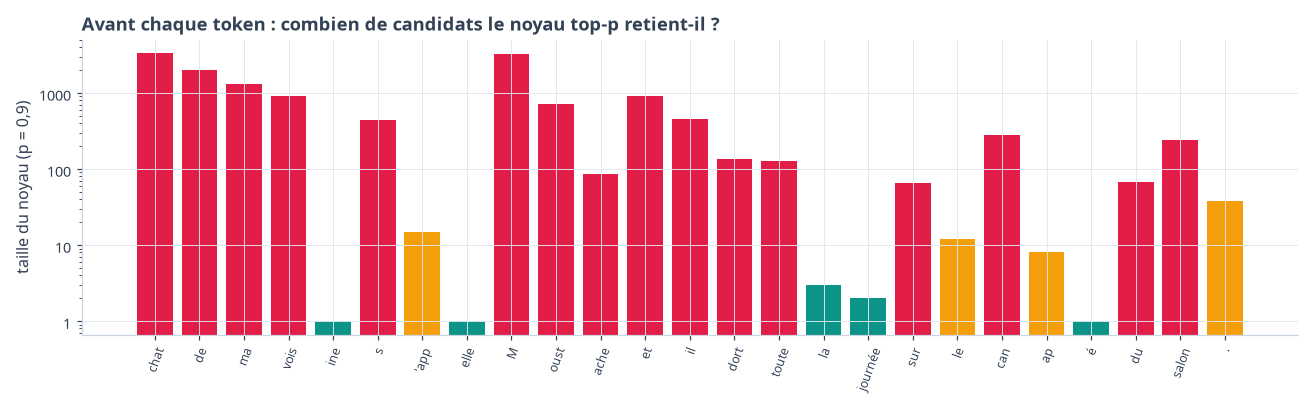

In [10]:
phrase = "Le chat de ma voisine s'appelle Moustache et il dort toute la journée sur le canapé du salon."
tb, mb = llm.load(BASE_QWEN)
ids = tb(phrase, return_tensors="pt")["input_ids"].to(mb.device)
with torch.no_grad():
    Z = mb(ids).logits[0].float().cpu().numpy()
sizes = [int(np.isfinite(m.top_p_filter(Z[t], 0.9)).sum()) for t in range(Z.shape[0] - 1)]
next_toks = [tb.decode([i]) for i in ids[0, 1:].tolist()]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(range(len(sizes)), sizes, color=[ROSE if s > 50 else (AMBER if s > 5 else TEAL) for s in sizes])
ax.set_yscale("log"); m.plain_log_axis(ax, "y")
ax.set_xticks(range(len(sizes)), [repr(t)[1:-1] for t in next_toks], rotation=70, fontsize=8)
ax.set_ylabel("taille du noyau (p = 0,9)")
ax.set_title("Avant chaque token : combien de candidats le noyau top-p retient-il ?")
plt.tight_layout(); plt.show()

Après « Le chat de ma », le noyau est large (beaucoup de suites possibles) ; au milieu
d'un mot ou d'une expression figée (« toute la journée »), il se réduit à un ou deux
tokens. Un top-k fixe serait trop large dans un cas et trop étroit dans l'autre : c'est
l'intérêt pratique du top-p, même si le livre note qu'il ne réduit pas le coût de la
softmax.

> **À retenir.** Top-k coupe à un nombre fixe de candidats, top-p à une masse de
> probabilité fixe (taille adaptative), min-p à un seuil relatif au favori. On les combine
> souvent avec la température (`m.sampling_distribution`).

## 5. Conditions d'arrêt (section *Stopping condition*)

Une génération longue coûte du temps et de l'argent (les API facturent les tokens de
sortie). On l'arrête par un **nombre maximal de tokens**, ou par des **tokens d'arrêt**
(fin de séquence, comme `<|im_end|>` chez Qwen). Le premier procédé coupe au milieu d'une
phrase, et casse les formats structurés :

In [11]:
demande_json = ('Donne une fiche JSON sur la ville de Lyon avec les clés "ville", "pays", "population" '
                'et "monuments" (liste de 3 noms). Réponds uniquement avec le JSON.')
rows = []
for max_tok in [20, 40, 200]:
    out = llm.chat(demande_json, max_new_tokens=max_tok)
    try:
        json.loads(out.strip().removeprefix("```json").removesuffix("```"))
        ok = "valide"
    except json.JSONDecodeError:
        ok = "invalide"
    rows.append({"max_new_tokens": max_tok, "fin de la sortie": "..." + short(out, 400)[-70:], "JSON": ok})
pd.DataFrame(rows)

,max_new_tokens,fin de la sortie,JSON
0,20,"...```json { ""ville"": ""Lyon"", ""pays"": ""France"",",invalide
1,40,"...yon"", ""pays"": ""France"", ""population"": ""2019"", ""monuments"": [""Château d",invalide
2,200,"..., ""monuments"": [""Château d'Orsay"", ""Musée Rodin"", ""Musée Rodin""] } ```",valide


> **À retenir.** Une limite de tokens maîtrise le coût et la latence, mais une sortie
> tronquée est souvent inutilisable (JSON sans accolade fermante). Dimensionnez la limite
> d'après la longueur attendue des réponses.

## 6. Test time compute (section *Test Time Compute*)

Au lieu d'une seule réponse, on en génère **plusieurs** et l'on choisit : c'est le *test
time compute* (dépenser plus de calcul à l'inférence). Pour choisir, le livre décrit :

- la **probabilité** de la sortie : la logprob d'une séquence est la somme des logprobs
  de ses tokens, $\log p(y) = \sum_t \log p(y_t \mid y_{<t})$, ce qui favorise les réponses
  courtes ; d'où la **logprob moyenne** $\frac{1}{|y|}\sum_t \log p(y_t \mid y_{<t})$ ;
- un **modèle de récompense** ou un **vérificateur** (cours 3) ;
- des **heuristiques** métier (la plus courte, une requête SQL valide...) ;
- le **vote majoritaire** (*self-consistency*, Wang et al., 2023) : pour une réponse
  exacte, on garde la plus fréquente.

Expérience : 24 problèmes d'arithmétique (deux opérations) posés à Qwen2.5-0.5B. Pour
chaque problème : une réponse gloutonne, puis 16 échantillons ($T = 0{,}8$, top-p 0,95),
dont on calcule aussi la logprob sous le modèle.

In [12]:
names = ["Alice", "Bob", "Chloé", "David", "Emma", "Farid", "Inès", "Hugo"]
items = ["pommes", "billes", "livres", "crayons", "timbres", "cartes"]
rp = np.random.default_rng(0)
problems = []
for i in range(24):
    a, b, c = int(rp.integers(3, 9)), int(rp.integers(4, 13)), int(rp.integers(2, 15))
    nm, it = names[i % 8], items[i % 6]
    problems.append((f"{nm} a {a} boîtes de {b} {it}. {nm} en donne {c}. Combien de {it} reste-t-il à {nm} ?",
                     a * b - c))
SYS_MATH = "Résous le problème étape par étape, puis termine par 'Réponse : <nombre>'."
N_SAMPLES = 16


def gen_logprobs(seqs, n_in):
    """Somme et nombre des logprobs (T = 1) des tokens générés, en s'arrêtant à la fin de séquence."""
    with torch.no_grad():
        lp = torch.log_softmax(model(seqs).logits[:, n_in - 1:-1].float(), -1)
    gen = seqs[:, n_in:]
    tok_lp = lp.gather(-1, gen[..., None])[..., 0]
    stop = torch.isin(gen, torch.tensor([tok.eos_token_id, tok.pad_token_id], device=gen.device))
    valid = (torch.cumsum(stop.int(), 1) - stop.int()) == 0     # jusqu'au premier token de fin inclus
    return (tok_lp * valid).sum(1).cpu().numpy(), valid.sum(1).cpu().numpy()


records = []
for qi, (question, answer) in enumerate(problems):
    msgs = [{"role": "system", "content": SYS_MATH}, {"role": "user", "content": question}]
    inp = llm._chat_inputs(tok, msgs).to(model.device)
    n_in = inp["input_ids"].shape[1]
    with torch.no_grad():
        g = model.generate(**inp, max_new_tokens=160, do_sample=False, pad_token_id=tok.pad_token_id)
        llm.seed_everything(qi)
        s = model.generate(**inp, max_new_tokens=160, do_sample=True, temperature=0.8, top_p=0.95,
                           num_return_sequences=N_SAMPLES, pad_token_id=tok.pad_token_id)
    greedy = m.extract_number(tok.decode(g[0, n_in:], skip_special_tokens=True))
    texts = tok.batch_decode(s[:, n_in:], skip_special_tokens=True)
    lp_sum, lp_len = gen_logprobs(s, n_in)
    for k, t in enumerate(texts):
        records.append(dict(pb=qi, truth=answer, greedy=greedy, k=k, answer=m.extract_number(t), text=t,
                            lp_sum=lp_sum[k], lp_mean=lp_sum[k] / max(lp_len[k], 1), n_tok=lp_len[k]))
samples = pd.DataFrame(records)
samples["correct"] = samples.answer == samples.truth
print(f"exemple d'échantillon : {short(samples.text.iloc[0], 230)}")
print(f"glouton : {(samples.groupby('pb').first().greedy == samples.groupby('pb').first().truth).mean():.0%} ; "
      f"un échantillon au hasard : {samples.correct.mean():.0%}")

exemple d'échantillon : 1. **Calculer les pommes existants dans les boîtes initiales:** - Alice a \(8\) boîtes avec \(9\) pommes dans chacune. - Il y a donc \(8 \times 9 = 72\) pommes dans les boîtes. 2. **Décoder la condition de la commande:** - La comm [...]
glouton : 29% ; un échantillon au hasard : 29%


Pour chaque budget $N \le 16$, on tire de nombreux sous-ensembles de $N$ échantillons et
l'on compare quatre règles de sélection : un seul échantillon, la meilleure logprob
moyenne, le vote majoritaire, et un **oracle** qui sait reconnaître la bonne réponse
(vérificateur parfait : borne supérieure, le « pass@N »).

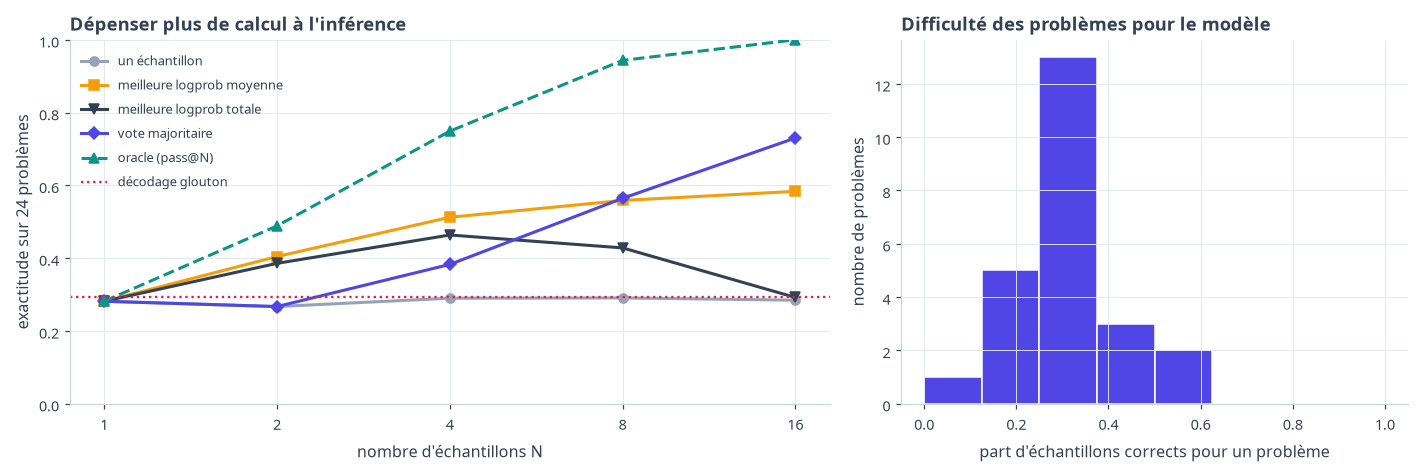

un échantillon               0.28
meilleure logprob moyenne    0.58
meilleure logprob totale     0.29
vote majoritaire             0.73
oracle (pass@N)              1.00


In [13]:
budgets = [1, 2, 4, 8, 16]
rs = np.random.default_rng(0)
curves = {k: [] for k in ["un échantillon", "meilleure logprob moyenne", "meilleure logprob totale",
                          "vote majoritaire", "oracle (pass@N)"]}
for N in budgets:
    acc = {k: [] for k in curves}
    for pb, grp in samples.groupby("pb"):
        for _ in range(100):
            sub = grp.iloc[rs.choice(N_SAMPLES, N, replace=False)]
            acc["un échantillon"].append(sub.correct.iloc[0])
            acc["meilleure logprob moyenne"].append(sub.loc[sub.lp_mean.idxmax(), "correct"])
            acc["meilleure logprob totale"].append(sub.loc[sub.lp_sum.idxmax(), "correct"])
            acc["vote majoritaire"].append(m.majority_vote(sub.answer.tolist())[0] == grp.truth.iloc[0])
            acc["oracle (pass@N)"].append(sub.correct.any())
    for k in curves:
        curves[k].append(np.mean(acc[k]))
greedy_acc = (samples.groupby("pb").first().greedy == samples.groupby("pb").first().truth).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax = axes[0]
for (k, v), c, mk in zip(curves.items(), [GRAY, AMBER, SLATE, INDIGO, TEAL], ["o", "s", "v", "D", "^"]):
    ax.plot(budgets, v, marker=mk, color=c, label=k, ls="--" if "oracle" in k else "-")
ax.axhline(greedy_acc, color=ROSE, ls=":", lw=1.5, label="décodage glouton")
ax.set_xscale("log", base=2); ax.set_xticks(budgets, budgets)
ax.set_xlabel("nombre d'échantillons N"); ax.set_ylabel("exactitude sur 24 problèmes")
ax.set_ylim(0, 1); ax.legend(fontsize=8.5, loc="upper left"); ax.set_title("Dépenser plus de calcul à l'inférence")
ax = axes[1]
per_pb = samples.groupby("pb").correct.mean()
ax.hist(per_pb, bins=np.linspace(0, 1, 9), color=INDIGO, edgecolor="white")
ax.set_xlabel("part d'échantillons corrects pour un problème"); ax.set_ylabel("nombre de problèmes")
ax.set_title("Difficulté des problèmes pour le modèle")
plt.tight_layout(); plt.show()
print(pd.Series({k: v[-1] for k, v in curves.items()}, name="exactitude à N = 16").round(2).to_string())

Lecture :

- un échantillon isolé n'est pas meilleur que le glouton, mais le **vote majoritaire**
  progresse nettement avec $N$ : les erreurs d'un petit modèle sont **dispersées** (chaque
  chemin de raisonnement se trompe différemment), alors que la bonne réponse revient
  souvent ; elle l'emporte dès qu'elle est la plus fréquente, même minoritaire ;
- la **logprob moyenne** aide un peu, mais nettement moins que le vote : la réponse que le
  modèle juge la plus probable n'est pas forcément juste ; la **logprob totale** n'aide
  guère, car elle favorise mécaniquement les raisonnements courts (souvent bâclés) ;
- l'**oracle** montre le potentiel d'un bon vérificateur : la bonne réponse figure souvent
  parmi les candidats. D'où l'intérêt des vérificateurs (OpenAI : l'équivalent d'un modèle
  30 fois plus gros) et des modèles de récompense ;
- le coût est linéaire : 16 échantillons coûtent environ 16 fois une génération (le
  prefill du prompt peut toutefois être partagé).

**Pourquoi le vote marche-t-il ?** Dans le cas binaire, si chaque tirage est juste avec
une probabilité $p > 1/2$ indépendamment des autres, la probabilité que la majorité de
$N$ tirages soit juste tend vers 1 (théorème du jury de Condorcet) ; si $p < 1/2$, elle
tend vers 0. Avec des réponses numériques, il suffit que la bonne réponse soit la plus
fréquente (exercice 2.10).

> **À retenir.** Générer plusieurs sorties et les agréger (vote, vérificateur, modèle de
> récompense) améliore la qualité au prix d'un coût proportionnel à $N$. Le vote
> majoritaire est simple et efficace pour les réponses exactes.

## 7. Sorties structurées (section *Structured Outputs*)

En production, on a souvent besoin d'un format précis : soit parce que la tâche l'exige
(*semantic parsing* : texte vers SQL ou regex, classification dans des classes données),
soit parce que la sortie est consommée par un programme (JSON pour un outil, chapitre 6).
Le livre classe les solutions par couche de la pile :

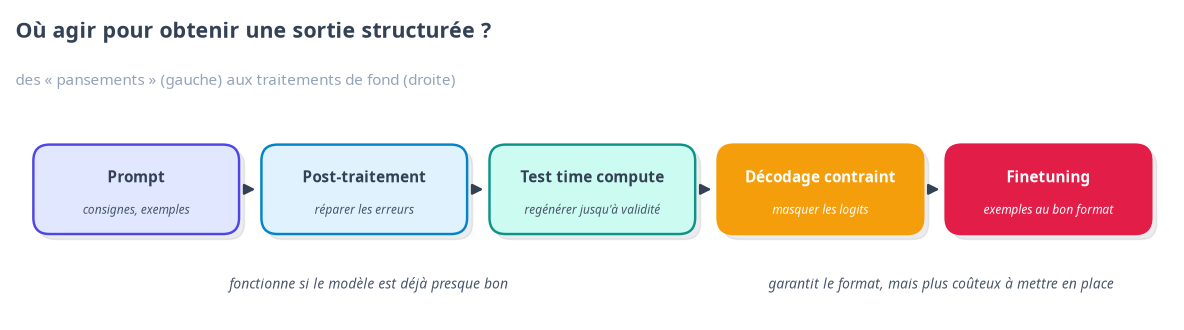

In [14]:
d = Diagram(13, 2.5, title="Où agir pour obtenir une sortie structurée ?",
            subtitle="des « pansements » (gauche) aux traitements de fond (droite)")
layers = [("pr", "Prompt", "consignes, exemples", INDIGO), ("pp", "Post-traitement", "réparer les erreurs", SKY),
          ("tt", "Test time compute", "regénérer jusqu'à validité", TEAL),
          ("cs", "Décodage contraint", "masquer les logits", AMBER), ("ft", "Finetuning", "exemples au bon format", ROSE)]
for i, (nm, t, sb, c) in enumerate(layers):
    d.box(nm, 1.4 + 2.55 * i, 1.45, t, sub=sb, color=c, w=2.3, h=1.0, fontsize=10, filled=(i >= 3))
for i in range(4):
    d.arrow(layers[i][0], layers[i + 1][0])
d.note(4.0, 0.4, "fonctionne si le modèle est déjà presque bon", fontsize=9)
d.note(10.4, 0.4, "garantit le format, mais plus coûteux à mettre en place", fontsize=9)
d.show()

**Le décodage contraint.** À chaque pas, on met à $-\infty$ les logits des tokens qui
violeraient le format, puis on échantillonne parmi les tokens restants. Il faut une
**grammaire** qui dise ce qui est permis à chaque position ; nous utilisons une
**expression régulière** et le test de **correspondance partielle** du module `regex` :
un texte est autorisé s'il est le préfixe d'au moins une chaîne du langage
(`m.regex_allows`). La fonction `m.constrained_generate` applique ce masque aux 400
tokens les plus probables à chaque pas (les bibliothèques comme outlines ou guidance
précompilent un automate sur tout le vocabulaire).

Tâche : extraire nom, ville et âge de huit courtes phrases, au format
`{"nom": "...", "ville": "...", "age": <entier>}`. On compare trois approches :
**prompt seul** (4 échantillons à $T = 0{,}8$ par phrase), **prompt + post-traitement**
(`m.repair_json` : retirer les balises de code, fermer les accolades...), et **décodage
contraint** par l'expression régulière du schéma.

deux sorties brutes du prompt seul :
   '```json { "nom": "Marie", "ville": "Lyon", "age": 34 } ```'
   '```json { "nom": "Marie", "ville": "Lyons", "age": 34 } ```'
sortie contrainte (phrase 1) : {"nom": "Marie Dubois", "ville": "Lyon", "age": 34}


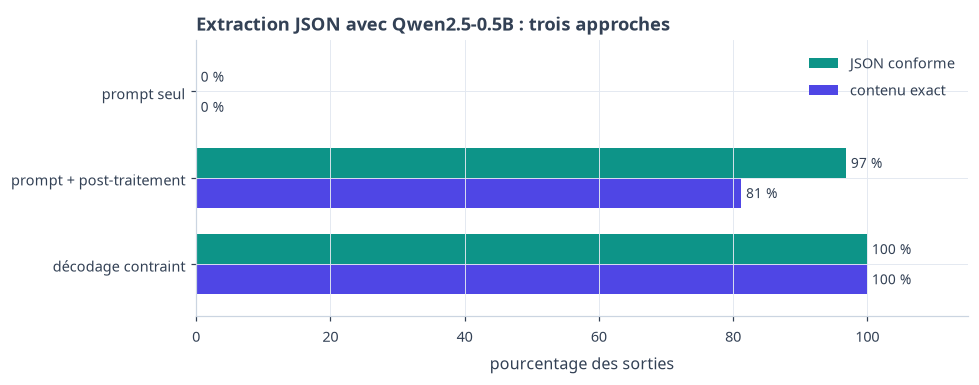

In [15]:
EXTRACT = [("Marie Dubois, 34 ans, habite à Lyon où elle travaille comme infirmière.", "Marie Dubois", "Lyon", 34),
           ("Installé à Bordeaux depuis peu, Karim Benali (41 ans) ouvre une librairie.", "Karim Benali", "Bordeaux", 41),
           ("La violoniste Sofia Rossi, 28 ans, vit désormais à Genève.", "Sofia Rossi", "Genève", 28),
           ("À 57 ans, Jean-Pierre Martin vit toujours à Lille, sa ville natale.", "Jean-Pierre Martin", "Lille", 57),
           ("Lucas Petit, un étudiant nantais de 22 ans, habite à Nantes.", "Lucas Petit", "Nantes", 22),
           ("Depuis Marseille, Amina Diallo, 45 ans, dirige une start-up.", "Amina Diallo", "Marseille", 45),
           ("Le chef Hiroshi Tanaka, 39 ans, a ouvert son restaurant à Strasbourg.", "Hiroshi Tanaka", "Strasbourg", 39),
           ("Élodie Garnier, 31 ans, vit à Rennes avec ses deux chats.", "Élodie Garnier", "Rennes", 31)]
SCHEMA_RE = r'\{"nom": "[^"\\\n]{1,40}", "ville": "[^"\\\n]{1,30}", "age": [1-9][0-9]?\}'
consigne = ('Extrais les informations du texte au format JSON avec exactement les clés "nom", "ville" et '
            '"age" (un entier).\n\nTexte : ')


def check(obj, truth):
    ok_schema = isinstance(obj, dict) and set(obj) == {"nom", "ville", "age"} and isinstance(obj.get("age"), int)
    exact = ok_schema and (obj["nom"], obj["ville"], obj["age"]) == truth
    return ok_schema, exact


res_rows, first_outputs = [], []
for i, (txt, *truth) in enumerate(EXTRACT):
    inp = llm._chat_inputs(tok, consigne + txt).to(model.device)
    llm.seed_everything(i)
    with torch.no_grad():
        s = model.generate(**inp, max_new_tokens=80, do_sample=True, temperature=0.8, num_return_sequences=4,
                           pad_token_id=tok.pad_token_id)
    for out in tok.batch_decode(s[:, inp["input_ids"].shape[1]:], skip_special_tokens=True):
        try:
            strict = json.loads(out)
        except json.JSONDecodeError:
            strict = None
        res_rows.append(("prompt seul", *check(strict, tuple(truth))))
        res_rows.append(("prompt + post-traitement", *check(m.repair_json(out), tuple(truth))))
        if len(first_outputs) < 2:
            first_outputs.append(out)
    cons_txt, steps = m.constrained_generate(consigne + txt, SCHEMA_RE, max_new_tokens=60)
    res_rows.append(("décodage contraint", *check(json.loads(cons_txt), tuple(truth))))
    if i == 0:
        steps0, cons0 = steps, cons_txt
res = pd.DataFrame(res_rows, columns=["méthode", "JSON conforme", "contenu exact"])
summary = res.groupby("méthode", sort=False)[["JSON conforme", "contenu exact"]].mean() * 100
print("deux sorties brutes du prompt seul :")
for o in first_outputs:
    print("  ", repr(short(o, 120)))
print("sortie contrainte (phrase 1) :", cons0)
fig, ax = plt.subplots(figsize=(9, 3.6))
summary.plot.barh(ax=ax, color=[TEAL, INDIGO], width=0.7)
annotate_bars(ax, "{:.0f} %"); ax.set_xlim(0, 115); ax.invert_yaxis()
ax.set_xlabel("pourcentage des sorties"); ax.set_ylabel("")
ax.set_title("Extraction JSON avec Qwen2.5-0.5B : trois approches"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

Le prompt seul produit rarement un JSON **directement** analysable : le modèle entoure sa
réponse de balises de code, ajoute du texte, ou change les clés. Le post-traitement
récupère beaucoup de ces cas (le livre cite le parseur YAML défensif de LinkedIn, passé
de 90 % à 99,99 % de sorties valides). Le décodage contraint garantit 100 % de sorties
**conformes au format** par construction ; il ne garantit pas que le **contenu** soit
juste, comme le rappelle le livre à propos des modes JSON des API.

Regardons le masque à l'œuvre au premier pas de la génération contrainte : les tokens
que le modèle préfère spontanément (il veut ouvrir un bloc de code avec des accents
graves, ou commencer une phrase), et les meilleurs tokens que l'expression régulière
autorise (ceux qui commencent par `{"`).

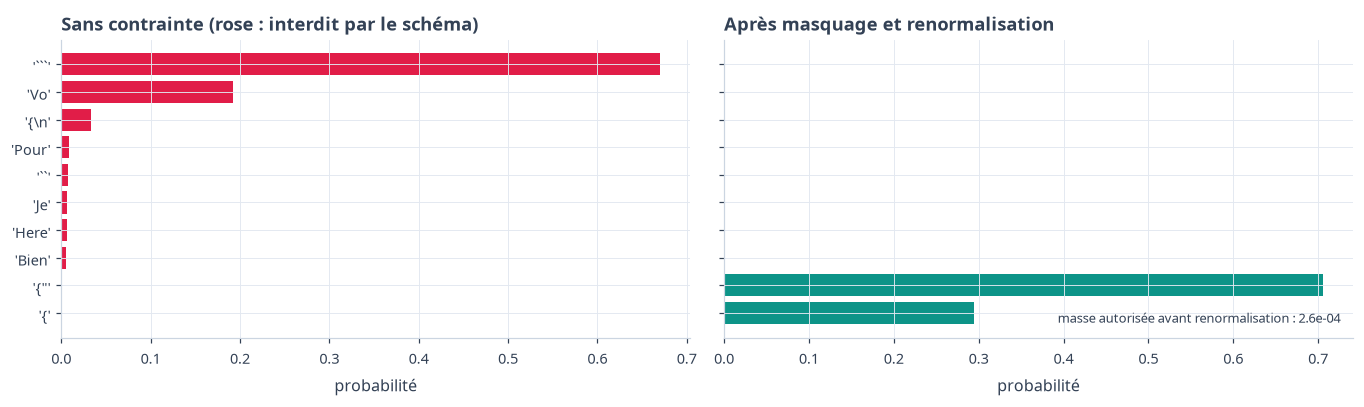

nombre de tokens autorisés parmi les 400 examinés, aux 8 premiers pas : [2, 3, 2, 58, 400, 395, 343, 395]


In [16]:
z0 = chat_logits(consigne + EXTRACT[0][0])
p0 = llm.softmax(z0)
vs = m.vocab_strings(llm.SMALL)
top400 = np.argsort(-z0)[:400]
ok400 = np.array([m.regex_allows(SCHEMA_RE, vs[i]) for i in top400])
cand0 = np.concatenate([top400[:8], top400[ok400][:4]])        # 8 favoris + 4 meilleurs tokens autorisés
allowed0 = np.array([m.regex_allows(SCHEMA_RE, vs[i]) for i in cand0])
p_masked = np.where(allowed0, p0[cand0], 0) / p0[top400[ok400]].sum()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
labs = [repr(vs[i]) for i in cand0]
axes[0].barh(labs[::-1], p0[cand0][::-1], color=[TEAL if a else ROSE for a in allowed0[::-1]])
axes[0].set_title("Sans contrainte (rose : interdit par le schéma)"); axes[0].set_xlabel("probabilité")
axes[1].barh(labs[::-1], p_masked[::-1], color=TEAL)
axes[1].set_title("Après masquage et renormalisation"); axes[1].set_xlabel("probabilité")
axes[1].text(0.98, 0.05, f"masse autorisée avant renormalisation : {p0[top400[ok400]].sum():.1e}",
             transform=axes[1].transAxes, ha="right", fontsize=8.5, color=SLATE)
plt.tight_layout(); plt.show()
print("nombre de tokens autorisés parmi les 400 examinés, aux 8 premiers pas :",
      [s.n_valid for s in steps0[:8]])

**Contraindre à une liste d'étiquettes.** Pour une classification, la contrainte la plus
simple consiste à **évaluer la logprob de chaque étiquette** autorisée et à prendre la
meilleure (`m.label_logprobs`) : la sortie est toujours une classe valide. Comparons à la
génération libre sur huit avis clients.

In [17]:
AVIS = [("Livraison rapide et produit conforme, je recommande !", "positif"),
        ("Le casque a cessé de fonctionner au bout de deux jours.", "négatif"),
        ("Le colis est arrivé mardi.", "neutre"),
        ("Service client injoignable, quelle déception.", "négatif"),
        ("Rapport qualité-prix imbattable, je suis ravi.", "positif"),
        ("La notice est en anglais et en allemand.", "neutre"),
        ("Franchement bof, ça ne vaut pas son prix.", "négatif"),
        ("Un vrai bonheur à utiliser au quotidien.", "positif")]
LABELS = ["positif", "négatif", "neutre"]
rows = []
for avis, truth in AVIS:
    q = f"Avis client : « {avis} »\nCe sentiment est-il positif, négatif ou neutre ? Réponds par un seul mot."
    free = llm.chat(q, max_new_tokens=20)
    scores = m.label_logprobs(q, [l.capitalize() for l in LABELS])
    rows.append({"avis": short(avis, 45), "vérité": truth, "génération libre": short(free, 45),
                 "libre valide ?": free.strip().lower().rstrip(".") in LABELS,
                 "contraint (logprobs)": max(scores, key=scores.get).lower()})
cls = pd.DataFrame(rows)
print(f"sorties libres directement valides : {cls['libre valide ?'].mean():.0%} ; "
      f"exactitude contrainte : {(cls['contraint (logprobs)'] == cls['vérité']).mean():.0%}")
cls

sorties libres directement valides : 75% ; exactitude contrainte : 88%


,avis,vérité,génération libre,libre valide ?,contraint (logprobs)
0,"Livraison rapide et produit conforme, je reco [...]",positif,Positif,True,positif
1,Le casque a cessé de fonctionner au bout de d [...],négatif,Négatif,True,négatif
2,Le colis est arrivé mardi.,neutre,Neutre,True,neutre
3,"Service client injoignable, quelle déception.",négatif,Nécessairement neutre.,False,neutre
4,"Rapport qualité-prix imbattable, je suis ravi [...]",positif,Positif,True,positif
5,La notice est en anglais et en allemand.,neutre,Neutre,True,neutre
6,"Franchement bof, ça ne vaut pas son prix.",négatif,Nécessaire de vérification pour déterminer le [...],False,négatif
7,Un vrai bonheur à utiliser au quotidien.,positif,Positif,True,positif


La génération libre ne respecte pas toujours la consigne (phrase entière, ponctuation,
autre mot) ; la version contrainte renvoie **toujours** une étiquette exploitable, et ses
erreurs éventuelles (les avis neutres sont les plus difficiles) sont des erreurs de
**jugement**, pas de format. Attention, l'exactitude contrainte dépend elle aussi du
prompt et même de l'écriture des étiquettes : lors de la mise au point de ce notebook,
des étiquettes en minuscules ou un prompt formulé autrement faisaient perdre plusieurs
points (c'est l'incohérence de la section 8). L'approche ultime, selon le livre, est le
**finetuning**, éventuellement avec une **tête de classification** ajoutée au modèle, qui
ne peut produire que les classes prévues (chapitre 7).

> **À retenir.** Le prompt et le post-traitement suffisent quand le modèle est presque
> bon ; le décodage contraint garantit le format en masquant les logits invalides à chaque
> pas (au prix d'une grammaire à écrire et d'un peu de latence) ; aucun ne garantit la
> justesse du contenu.

## 8. Nature probabiliste : l'incohérence (sections *The Probabilistic Nature of AI* et *Inconsistency*)

Si le modèle pense que la cuisine vietnamienne a 70 % de chances d'être la meilleure du
monde, il le dira 70 % du temps : il est **probabiliste**. Cela le rend précieux pour la
création, et pénible pour tout le reste. Le livre distingue deux formes d'incohérence :

1. **même entrée, sorties différentes** ;
2. **entrée légèrement différente, sortie très différente**.

Reproduisons l'exemple du livre (noter une dissertation, 3/5 puis 5/5) : on lit
directement la distribution du modèle sur les notes « 1 » à « 5 », puis on modifie
légèrement la formulation du prompt.

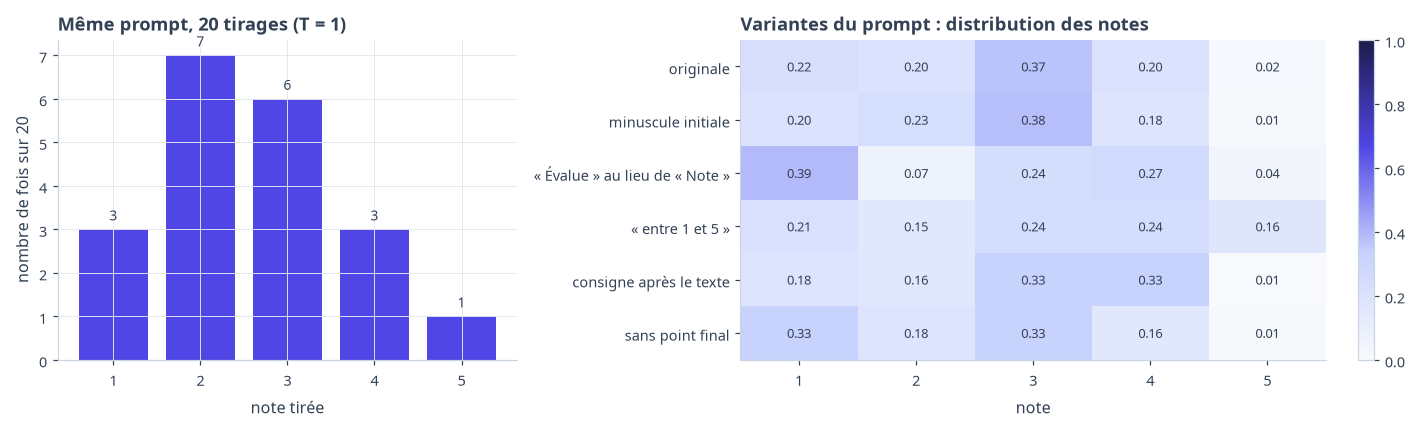

note gloutonne par variante : {'originale': '3', 'minuscule initiale': '3', '« Évalue » au lieu de « Note »': '1', '« entre 1 et 5 »': '3', 'consigne après le texte': '3', 'sans point final': '1'}


In [18]:
essai = ("Les réseaux sociaux rapprochent les gens car ils permettent de rester en contact avec sa famille. "
         "Mais ils peuvent aussi isoler, car on passe moins de temps avec les personnes autour de soi. "
         "En conclusion, il faut les utiliser avec modération.")
variantes = {
    "originale": f"Note cette courte dissertation de 1 à 5. Réponds uniquement par un chiffre.\n\n{essai}",
    "minuscule initiale": f"note cette courte dissertation de 1 à 5. Réponds uniquement par un chiffre.\n\n{essai}",
    "« Évalue » au lieu de « Note »": f"Évalue cette courte dissertation de 1 à 5. Réponds uniquement par un chiffre.\n\n{essai}",
    "« entre 1 et 5 »": f"Note cette courte dissertation entre 1 et 5. Réponds uniquement par un chiffre.\n\n{essai}",
    "consigne après le texte": f"{essai}\n\nNote cette courte dissertation de 1 à 5. Réponds uniquement par un chiffre.",
    "sans point final": f"Note cette courte dissertation de 1 à 5. Réponds uniquement par un chiffre\n\n{essai}",
}
notes = ["1", "2", "3", "4", "5"]
dist = {}
for nom, pr in variantes.items():
    sc = m.label_logprobs(pr, notes)
    dist[nom] = llm.softmax(np.array([sc[n] for n in notes]))
D = pd.DataFrame(dist, index=notes).T
r8 = np.random.default_rng(8)
tirages = r8.choice(notes, size=20, p=D.loc["originale"].values)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw=dict(width_ratios=[1, 1.4]))
ax = axes[0]
cnt = pd.Series(tirages).value_counts().reindex(notes, fill_value=0)
ax.bar(notes, cnt.values, color=INDIGO)
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("note tirée"); ax.set_ylabel("nombre de fois sur 20"); ax.set_title("Même prompt, 20 tirages (T = 1)")
ax = axes[1]
im = ax.imshow(D.values, cmap="aie_seq", vmin=0, vmax=1, aspect="auto"); ax.grid(False)
ax.set_xticks(range(5), notes); ax.set_yticks(range(len(D)), D.index)
for i in range(D.shape[0]):
    for j in range(5):
        ax.text(j, i, f"{D.values[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if D.values[i, j] > 0.5 else SLATE)
ax.set_xlabel("note"); ax.set_title("Variantes du prompt : distribution des notes")
plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.show()
print("note gloutonne par variante :", {k: notes[int(np.argmax(v))] for k, v in dist.items()})

Avec le même prompt, les notes tirées varient d'un appel à l'autre (premier scénario).
Et des retouches anodines (une majuscule, un synonyme, l'ordre consigne-texte) déplacent
la distribution, parfois au point de changer la note gloutonne (second scénario).

**Remèdes.** Pour le premier scénario : mettre la réponse en **cache**, fixer la
température (0), le top-p, le top-k et la **graine** aléatoire. Même ainsi, le livre
prévient que le matériel peut changer le résultat : les calculs en virgule flottante ne
sont pas associatifs, et l'ordre des opérations dépend du GPU, de la taille de batch ou
de la bibliothèque. Démonstration minimale :

In [19]:
vals = np.random.default_rng(0).normal(size=100_000).astype(np.float32)
s1 = np.sum(vals)
s2 = np.sum(vals[np.random.default_rng(1).permutation(vals.size)])
s3 = float(np.sum(vals.astype(np.float64)))
print(f"somme dans l'ordre : {s1:.6f} | même somme, autre ordre : {s2:.6f} | en float64 : {s3:.6f}")

somme dans l'ordre : -90.825134 | même somme, autre ordre : -90.825089 | en float64 : -90.825078


Ces écarts infimes suffisent, quand deux tokens ont des logits presque égaux, à faire
basculer un argmax et donc toute la suite de la génération. Pour le second scénario,
seuls des prompts soignés (chapitre 5) et une mémoire (chapitre 6) aident.

> **À retenir.** Un modèle échantillonné est incohérent par nature ; fixer température et
> graine réduit le premier type d'incohérence sans l'éliminer (matériel), et la
> sensibilité au prompt se mesure : testez plusieurs formulations avant de déployer.

## 9. Les hallucinations (section *Hallucination*)

Une hallucination est une réponse non fondée sur les faits. Le livre présente deux
hypothèses complémentaires :

1. **L'auto-illusion** (*self-delusion*, Ortega et al., 2021) : le modèle ne distingue pas
   ce qu'on lui donne de ce qu'il a lui-même généré. Une première phrase erronée devient
   un « fait » sur lequel il construit, d'où l'effet boule de neige (*snowballing
   hallucinations*, Zhang et al., 2023).
2. **Le décalage de connaissances** (Leo Gao, John Schulman) : en SFT, on apprend au
   modèle à imiter des réponses qui utilisent des connaissances des annotateurs qu'il n'a
   pas, ce qui lui apprend à inventer.

**Boule de neige.** On impose au modèle le début de sa réponse (une affirmation fausse)
et on le laisse continuer. 9677 n'est pas divisible par 13 ($13 \times 744 = 9672$).

In [20]:
def continue_assistant(user, prefix, max_new_tokens=60):
    text = tok.apply_chat_template([{"role": "user", "content": user}], tokenize=False,
                                   add_generation_prompt=True) + prefix
    ids = tok(text, return_tensors="pt", add_special_tokens=False).to(model.device)
    with torch.no_grad():
        out = model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
    return tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True)


q_div = "Is 9677 divisible by 13? Answer and justify briefly."
print("sans préfixe          :", short(llm.chat(q_div, max_new_tokens=60), 220))
print("préfixe « Yes, »      : Yes, 9677 is divisible by 13 because" +
      short(continue_assistant(q_div, "Yes, 9677 is divisible by 13 because"), 200))
print("préfixe « No, »       : No, 9677 is not divisible by 13 because" +
      short(continue_assistant(q_div, "No, 9677 is not divisible by 13 because"), 200))
print(f"vérification : 9677 / 13 = {9677 / 13:.4f} ; 13 x 744 = {13 * 744}")

sans préfixe          : To determine if 9677 is divisible by 13, we can use the divisibility rule for 13. The rule states that a number is divisible by 13 if the difference between the sum of its digits in the odd positions and the sum of its d [...]


préfixe « Yes, »      : Yes, 9677 is divisible by 13 becausewhen we divide 9677 by 13, we get: \[ 9677 \div 13 = 745 \] Since the result is an integer (745), it confirms that 9677 is indeed divisible by 13


préfixe « No, »       : No, 9677 is not divisible by 13 becausethe last digit of 9677 is 7, which is not divisible by 3 (since \(7 \div 3 = 2\) remainder \(1\)). Additionally, to check divisibility by 13, we can use the rule that a number is divisible by
vérification : 9677 / 13 = 744.3846 ; 13 x 744 = 9672


Quel que soit le début imposé, le modèle produit une justification qui lui est
**cohérente**, au besoin avec un calcul inventé : il traite sa propre sortie comme une
donnée. (Le modèle de 0,5 milliard de paramètres n'est pas fiable en arithmétique : sa
réponse spontanée peut elle-même être fausse.) Même chose pour une biographie, comme
l'exemple du livre (« Chip Huyen est architecte ») :

In [21]:
print("Qui est Chip Huyen ? -> Chip Huyen est une architecte" +
      short(continue_assistant("Qui est Chip Huyen ?", "Chip Huyen est une architecte", 50), 220))

Qui est Chip Huyen ? -> Chip Huyen est une architecteet ingénieure de l'information numérique, spécialisée dans le domaine des applications mobiles et des services cloud. Voici quelques informations sur lui : 1. Formation : Elle a obtenu son diplôme d'ingénieur en informat


**Mesurer les hallucinations.** On pose au modèle 8 questions factuelles **réelles** et
8 questions sur des entités **inventées** (roman, pays, physicienne, élément chimique...).
Une réponse assurée à une question sur une entité inexistante est une hallucination. On
compare deux prompts système : neutre, et « si tu ne sais pas, dis-le ».

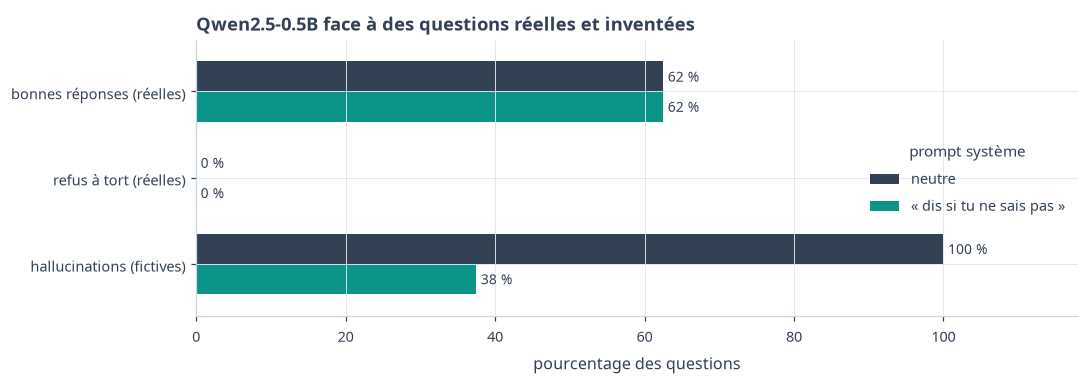

,question,réponse
8,Qui a écrit le roman « Les Horloges de Valdemor » ?,"Le roman ""Les Horloges de Valdemor"" est écrit par l'auteur français Jean-Paul Sartre. Il est un texte auto..."
9,Quelle est la capitale de la république de Norvalie ?,La capitale de la République de Norvalie est Saint-Pétersbourg (en russe : Saint-Péter). Cette ville est s...
10,Quel prix a reçu la physicienne Hélène Dravignac en 1987 pour ses travaux sur les cristaux temporels ?,"Hélène Dravignac a reçu le Prix Nobel de Physique en 1987 pour son travail sur les ""cristaux temporels"". C..."
11,En quelle année a été fondée la ville de Port-Ambrelle ?,La ville de Port-Ambrelle est fondée en 1964. Elle est située dans le département du Haut-Loire en France ...


In [22]:
REELLES = [("Qui a écrit « Les Misérables » ?", "hugo"), ("Quelle est la capitale de l'Australie ?", "canberra"),
           ("Qui a peint la Joconde ?", "vinci"), ("En quelle année l'homme a-t-il marché sur la Lune pour la première fois ?", "1969"),
           ("Quel est le plus grand océan du monde ?", "pacifique"), ("Qui a formulé la théorie de la relativité ?", "einstein"),
           ("Quel est le symbole chimique de l'or ?", "au"), ("Dans quel pays se trouve le Machu Picchu ?", "pérou")]
FICTIVES = ["Qui a écrit le roman « Les Horloges de Valdemor » ?", "Quelle est la capitale de la république de Norvalie ?",
            "Quel prix a reçu la physicienne Hélène Dravignac en 1987 pour ses travaux sur les cristaux temporels ?",
            "En quelle année a été fondée la ville de Port-Ambrelle ?",
            "Qui a peint le tableau « Le Banquet des sept lanternes » ?", "Quel est le symbole chimique du zorvium ?",
            "Quelle est la théorie principale de l'économiste Bertrand Valoisier ?",
            "Dans quel pays se trouve le lac Ostravel ?"]
REFUS = ["je ne sais pas", "n'existe pas", "pas d'information", "aucune information", "je ne connais pas", "fictif",
         "fictive", "inconnu", "pas de données", "je n'ai pas", "pas en mesure", "aucune trace", "pas connu",
         "n'ai pas d'informations", "désolé", "imaginaire", "pas trouvé", "n'est pas un", "n'est pas une"]
is_refusal = lambda t: any(k in t.lower() for k in REFUS)
SYSTEMS = {"neutre": None,
           "« dis si tu ne sais pas »": "Réponds de façon concise et véridique. Si tu n'es pas sûr de la réponse "
                                         "ou si la question porte sur quelque chose qui n'existe pas, réponds "
                                         "« Je ne sais pas »."}
rows = []
for sname, system in SYSTEMS.items():
    for q, key in REELLES:
        a = llm.chat(q, system=system, max_new_tokens=50)
        rows.append(dict(prompt=sname, type="réelle", question=q, réponse=a, refus=is_refusal(a),
                         juste=key in a.lower()))
    for q in FICTIVES:
        a = llm.chat(q, system=system, max_new_tokens=50)
        rows.append(dict(prompt=sname, type="fictive", question=q, réponse=a, refus=is_refusal(a), juste=False))
H = pd.DataFrame(rows)
H["hallucination"] = (H.type == "fictive") & ~H.refus
summary_h = pd.DataFrame({
    "bonnes réponses (réelles)": H[H.type == "réelle"].groupby("prompt", sort=False).juste.mean(),
    "refus à tort (réelles)": H[H.type == "réelle"].groupby("prompt", sort=False).refus.mean(),
    "hallucinations (fictives)": H[H.type == "fictive"].groupby("prompt", sort=False).hallucination.mean()}) * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
summary_h.T.plot.barh(ax=ax, color=[SLATE, TEAL], width=0.7)
annotate_bars(ax, "{:.0f} %"); ax.set_xlim(0, 118); ax.invert_yaxis()
ax.set_xlabel("pourcentage des questions"); ax.legend(title="prompt système", loc="center right")
ax.set_title("Qwen2.5-0.5B face à des questions réelles et inventées")
plt.tight_layout(); plt.show()
H[(H.type == "fictive") & (H.prompt == "neutre")][["question", "réponse"]].head(4).assign(
    réponse=lambda df: df.réponse.map(lambda t: short(t, 110)))

Le petit modèle répond avec aplomb à la plupart des questions sur des entités qui
n'existent pas : il invente un auteur, une capitale, un prix Nobel, une date de
fondation. Le prompt « dis si tu ne sais pas », que le livre mentionne comme une parade
courante, réduit nettement les hallucinations dans cette expérience, sans les supprimer.
Il a un coût potentiel à surveiller : des **refus à tort** sur des questions réelles
(aucun ici, mais sur 8 questions seulement). Un modèle de 0,5 milliard de paramètres
« sait » mal ce qu'il sait, et ne répond correctement qu'à une partie des questions
réelles.

**Détecter plutôt qu'empêcher : la cohérence entre échantillons.** Si le modèle connaît la
réponse, plusieurs échantillons tendent à converger ; s'il invente, chaque tirage invente
autre chose. On tire 6 réponses à $T = 1$ par question et l'on mesure leur similarité
moyenne (cosinus entre plongements multilingues, chapitre 3), une idée proche de
SelfCheckGPT (Manakul et al., 2023).

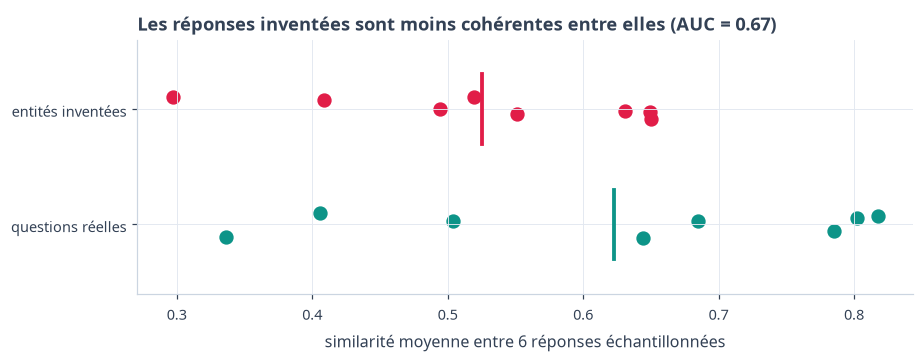

In [23]:
def consistency(q, n=6, seed=0):
    msgs = [{"role": "user", "content": q}]
    inp = llm._chat_inputs(tok, msgs).to(model.device)
    llm.seed_everything(seed)
    with torch.no_grad():
        s = model.generate(**inp, max_new_tokens=40, do_sample=True, temperature=1.0, num_return_sequences=n,
                           pad_token_id=tok.pad_token_id)
    outs = tok.batch_decode(s[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)
    E = llm.embed(outs, llm.EMBED_MULTI)
    S = E @ E.T
    return S[np.triu_indices(n, 1)].mean()


cons = pd.DataFrame([dict(type="réelle", score=consistency(q, seed=i)) for i, (q, _) in enumerate(REELLES)] +
                    [dict(type="fictive", score=consistency(q, seed=i)) for i, q in enumerate(FICTIVES)])
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(cons.type == "réelle", cons.score)
fig, ax = plt.subplots(figsize=(8.5, 3.4))
for j, (typ, c) in enumerate([("réelle", TEAL), ("fictive", ROSE)]):
    v = cons[cons.type == typ].score
    ax.scatter(v, np.full(len(v), j) + np.random.default_rng(j).uniform(-0.12, 0.12, len(v)), s=70, color=c)
    ax.plot([v.mean()] * 2, [j - 0.3, j + 0.3], color=c, lw=2.5)
ax.set_yticks([0, 1], ["questions réelles", "entités inventées"]); ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("similarité moyenne entre 6 réponses échantillonnées")
ax.set_title(f"Les réponses inventées sont moins cohérentes entre elles (AUC = {auc:.2f})")
plt.tight_layout(); plt.show()

Les réponses aux questions réelles se ressemblent davantage d'un tirage à l'autre que les
réponses inventées : la **variabilité** entre échantillons est un signal (imparfait) de
connaissance, exploitable pour signaler une réponse douteuse plutôt que de la servir.
Sur 16 questions seulement, l'AUC est une estimation très bruitée ; le chapitre 4
reviendra sur la détection et la mesure des hallucinations.

> **À retenir.** Les hallucinations viennent en partie de ce que le modèle construit sur
> ses propres sorties (boule de neige) et de ce qu'on lui a appris à imiter des
> connaissances qu'il n'a pas. On les atténue (prompts, réponses concises, RAG au
> chapitre 6) et on peut en détecter une partie par la cohérence entre échantillons.

## Synthèse

- **Fondamentaux.** Le modèle produit des logits, la softmax en fait une distribution sur
  tout le vocabulaire ; glouton = argmax, échantillonnage = tirage.
- **Température.** $p \propto e^{x/T}$ : l'entropie croît avec $T$ ; basse pour la
  cohérence, plus haute pour la diversité.
- **Logprobs.** Indispensables pour éviter le sous-dépassement ; logprob d'une séquence =
  somme des logprobs des tokens.
- **Top-k / top-p / min-p.** Couper la traîne de la distribution ; le noyau top-p s'adapte
  au contexte.
- **Arrêt.** Limite de tokens ou tokens d'arrêt ; attention aux formats tronqués.
- **Test time compute.** Le vote majoritaire sur 16 échantillons améliore nettement un
  petit modèle sur des problèmes d'arithmétique ; la logprob est un mauvais sélecteur ;
  un bon vérificateur aurait un potentiel bien plus grand (oracle).
- **Sorties structurées.** Prompt et post-traitement améliorent la validité ; le
  décodage contraint la garantit par masquage des logits.
- **Nature probabiliste.** Incohérence (même prompt ou prompt voisin) et hallucinations
  (boule de neige, entités inventées) se mesurent ; la cohérence entre échantillons aide
  à détecter les secondes.

**Liens.** Le chapitre 3 formalise entropie, perplexité et l'IA comme juge ; le chapitre 4
mesure hallucinations et respect des formats ; le chapitre 5 traite la sensibilité au
prompt ; le chapitre 6 l'ancrage par RAG et les agents qui consomment des sorties
structurées ; le chapitre 9 l'optimisation de l'inférence.

In [24]:
llm.free_gpu()